Titanic Survival Prediction - Exploratory Data Analysis

In [2]:
import pandas as pd #for data manipulation
import numpy as np
import matplotlib.pyplot as plt #foundational plotting in Python
import seaborn as sns #for visualisations

#plot style
sns.set_theme(style="whitegrid") #sets a visual global theme; white background, grey gridlines, suitable fonts etc.
plt.rcParams["figure.figsize"] = (10, 6) #sets the default figure size to 10" by 6"
plt.rcParams["figure.dpi"] = 100 #sets the resolution to 100 dots per inch

%matplotlib inline 
#a jupyter magic command that tells the notebook to show figures inside the notebook, under the cell that creates them instead of opening another window

In [3]:
df = pd.read_csv("data/train.csv") 
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)

Dataset shape: 891 rows, 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [5]:
df.info() #the datatypes of each column, the count of non-null values

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
df.describe() #basic statistics of the columns with numerical values

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(include="object") #stats of categorical columns

C:\Users\there\AppData\Local\Temp\ipykernel_19280\3146410535.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") #stats of categorical columns


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [9]:
#count and percentage of the missing values

#creates a new dataframe from a dictionary, where each key becomes a value pair
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(), #this is a series that becomes the first column; the sum is the number of missing values per column. the series is indexed by column name
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2) #essentially the same thing but as a percentage
})
#both series have the same index so pandas lines them up automatically


missing = missing[missing["Missing Count"] > 0].sort_values("Missing %", ascending=False)
print("Columns with missing values:")
missing

Columns with missing values:


,Missing Count,Missing %
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


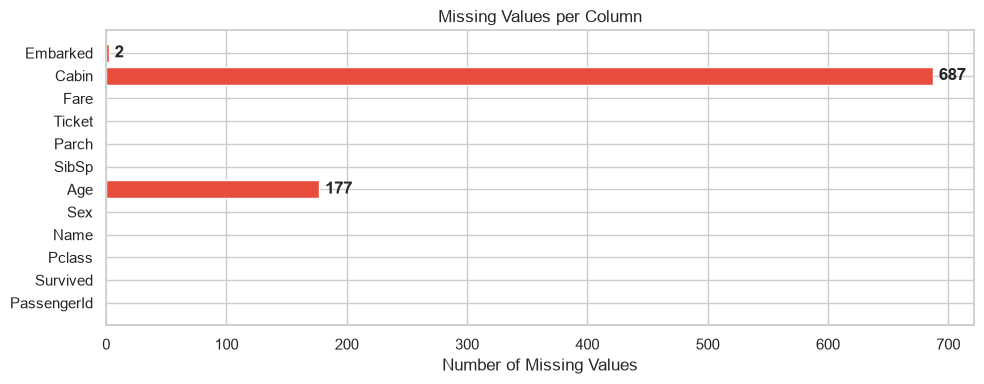

In [10]:
#visualising the missing values
fig, ax = plt.subplots(figsize=(10, 4)) #creating a figure
colors = ["#e74c3c" if df[col].isnull().any() else "#2ecc71" for col in df.columns]
ax.barh(df.columns, df.isnull().sum(), color=colors)
ax.set_xlabel("Number of Missing Values")
ax.set_title("Missing Values per Column")
for i, v in enumerate(df.isnull().sum()):
    if v > 0:
        ax.text(v + 5, i, str(v), va="center", fontweight="bold")
        
plt.tight_layout()
plt.show()

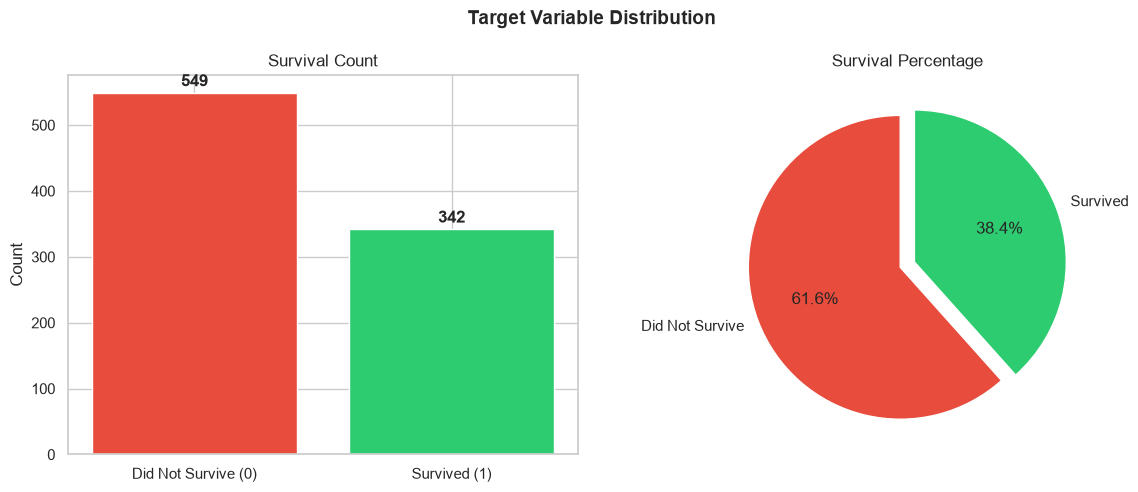


Survival rate: 38.38%
Death rate: 61.62%


In [13]:
#target variable analysis
#survival distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#count plot
survived_counts = df["Survived"].value_counts()
axes[0].bar(["Did Not Survive (0)", "Survived (1)"], survived_counts.values,
            color=["#e74c3c", "#2ecc71"])
axes[0].set_title("Survival Count")
axes[0].set_ylabel("Count")
for i, v in enumerate(survived_counts.values):
    axes[0].text(i, v + 10, str(v), ha="center", fontweight="bold")
    
#piechart time
axes[1].pie(survived_counts.values, labels=["Did Not Survive", "Survived"],
            autopct="%1.1f%%", colors=["#e74c3c", "#2ecc71"],
            startangle=90, explode=(0.05, 0.05))
axes[1].set_title("Survival Percentage")

plt.suptitle("Target Variable Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nSurvival rate: {df['Survived'].mean():.2%}")
print(f"Death rate: {1 - df['Survived'].mean():.2%}")